# IN1002B: DESARROLLO DE PROYECTOS DE ANÁLISIS DE DATOS

## Contenido

1. Leer archivo
1. Preprocesar los datos
1. Análisis y Visualización
1. Reporte de Procedimientos y Archivo Final de la Base de Datos

In [1]:
# importamos librerías
import warnings
warnings.filterwarnings("ignore")

In [2]:
import numpy as np # librería para poder usar arreglos
import pandas as pd # librería para poder usar DataFrames (tablas)
import matplotlib.pyplot as plt # to plot
import seaborn as sns # to plot
import random
import string
from scipy import stats # pruebas de normalidad, Q-Q plot y correlación

## 1. Leer archivo

In [3]:
dataSet = pd.read_csv("Churn.csv", header=0)

In [4]:
print(dataSet.head())
print("")
print(dataSet.info())
print("")
print(dataSet.isnull().sum())
print("")
print(dataSet.describe())

   No.  customerID  gender  ...  MonthlyCharges TotalCharges Churn
0    1  7590-VHVEG  Female  ...           29.85        39.65    No
1    2  5575-GNVDE    Male  ...           56.95      2339.30    No
2    3  3668-QPYBK    Male  ...           53.85        97.00   Yes
3    4  7795-CFOCW    Male  ...           42.30      1596.60    No
4    5  9237-HQITU  Female  ...           70.70       181.65   Yes

[5 rows x 22 columns]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   No.               7043 non-null   int64  
 1   customerID        7043 non-null   object 
 2   gender            7043 non-null   object 
 3   SeniorCitizen     7043 non-null   int64  
 4   Partner           7043 non-null   object 
 5   Dependents        7043 non-null   object 
 6   tenure            7023 non-null   float64
 7   PhoneService      6923 non-null   objec

## 2. Preprocesar los datos

In [5]:
filter_data = dataSet[dataSet["tenure"].notna()]
print(filter_data.head())
print("")
print(filter_data.info())
print("")
print(filter_data.isnull().sum())
print("")
print(filter_data.describe())

   No.  customerID  gender  ...  MonthlyCharges TotalCharges Churn
0    1  7590-VHVEG  Female  ...           29.85        39.65    No
1    2  5575-GNVDE    Male  ...           56.95      2339.30    No
2    3  3668-QPYBK    Male  ...           53.85        97.00   Yes
3    4  7795-CFOCW    Male  ...           42.30      1596.60    No
4    5  9237-HQITU  Female  ...           70.70       181.65   Yes

[5 rows x 22 columns]

<class 'pandas.core.frame.DataFrame'>
Index: 7023 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   No.               7023 non-null   int64  
 1   customerID        7023 non-null   object 
 2   gender            7023 non-null   object 
 3   SeniorCitizen     7023 non-null   int64  
 4   Partner           7023 non-null   object 
 5   Dependents        7023 non-null   object 
 6   tenure            7023 non-null   float64
 7   PhoneService      6904 non-null   object 
 8

In [6]:
print(dataSet.describe())
print("")
print(filter_data.describe())

               No.  SeniorCitizen       tenure  MonthlyCharges  TotalCharges
count  7043.000000    7043.000000  7023.000000     7033.000000   7032.000000
mean   3522.000000       0.162147    32.380749       64.761702   2283.300441
std    2033.283305       0.368612    24.593771       30.111435   2266.771362
min       1.000000       0.000000     0.000000       18.250000     18.800000
25%    1761.500000       0.000000     9.000000       35.450000    401.450000
50%    3522.000000       0.000000    29.000000       70.350000   1397.475000
75%    5282.500000       0.000000    55.000000       89.850000   3794.737500
max    7043.000000       1.000000    72.000000      118.750000   8684.800000

               No.  SeniorCitizen       tenure  MonthlyCharges  TotalCharges
count  7023.000000    7023.000000  7023.000000     7013.000000   7012.000000
mean   3522.953866       0.162324    32.380749       64.814145   2285.815573
std    2032.996727       0.368774    24.593771       30.127075   2269.36791

In [7]:
df = dataSet.copy()
df = df[df["SeniorCitizen"].notna()]
df = df[df["StreamingTV"].notna()]
df = df[df["StreamingMovies"].notna()]
df = df[df["Contract"].notna()]
df = df[df["Churn"].notna()]
df = df[df["tenure"].notna()]
df = df[df["MonthlyCharges"].notna()]
df = df[df["TotalCharges"].notna()]

In [8]:
print(df.head())
print("")
print(df.info())
print("")
print(df.isnull().sum())
print("")
print(df.describe())

   No.  customerID  gender  ...  MonthlyCharges TotalCharges Churn
0    1  7590-VHVEG  Female  ...           29.85        39.65    No
1    2  5575-GNVDE    Male  ...           56.95      2339.30    No
2    3  3668-QPYBK    Male  ...           53.85        97.00   Yes
3    4  7795-CFOCW    Male  ...           42.30      1596.60    No
4    5  9237-HQITU  Female  ...           70.70       181.65   Yes

[5 rows x 22 columns]

<class 'pandas.core.frame.DataFrame'>
Index: 7002 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   No.               7002 non-null   int64  
 1   customerID        7002 non-null   object 
 2   gender            7002 non-null   object 
 3   SeniorCitizen     7002 non-null   int64  
 4   Partner           7002 non-null   object 
 5   Dependents        7002 non-null   object 
 6   tenure            7002 non-null   float64
 7   PhoneService      6885 non-null   object 
 8

In [9]:
print(dataSet.describe())
print("")
print(filter_data.describe())
print("")
print(df.describe())

               No.  SeniorCitizen       tenure  MonthlyCharges  TotalCharges
count  7043.000000    7043.000000  7023.000000     7033.000000   7032.000000
mean   3522.000000       0.162147    32.380749       64.761702   2283.300441
std    2033.283305       0.368612    24.593771       30.111435   2266.771362
min       1.000000       0.000000     0.000000       18.250000     18.800000
25%    1761.500000       0.000000     9.000000       35.450000    401.450000
50%    3522.000000       0.000000    29.000000       70.350000   1397.475000
75%    5282.500000       0.000000    55.000000       89.850000   3794.737500
max    7043.000000       1.000000    72.000000      118.750000   8684.800000

               No.  SeniorCitizen       tenure  MonthlyCharges  TotalCharges
count  7023.000000    7023.000000  7023.000000     7013.000000   7012.000000
mean   3522.953866       0.162324    32.380749       64.814145   2285.815573
std    2032.996727       0.368774    24.593771       30.127075   2269.36791

## 3. Análisis y Visualización

### Hipótesis
El cargo mensual (`MonthlyCharges`) y la antigüedad del cliente (`tenure`) influyen directamente en el cargo total acumulado (`TotalCharges`), mientras que la modalidad de contrato mes a mes (`Month-to-month`) concentra la mayor proporción de clientes; además, las variables numéricas `tenure`, `MonthlyCharges` y `TotalCharges` no siguen una distribución normal.

### 3.1 Diagramas de barras para `SeniorCitizen`, `StreamingTV`, `StreamingMovies`, `Contract` y `Churn` y determinación de su frecuencia

In [10]:
cat_vars = ["SeniorCitizen", "StreamingTV", "StreamingMovies", "Contract", "Churn"]

print("Dimensiones de df limpio:", df.shape)
print("")
for v in cat_vars:
    print(f"Clases únicas en {v}: {df[v].unique()}")

Dimensiones de df limpio: (7002, 22)

Clases únicas en SeniorCitizen: [0 1]
Clases únicas en StreamingTV: ['No' 'Yes' 'No internet service']
Clases únicas en StreamingMovies: ['No' 'Yes' 'No internet service']
Clases únicas en Contract: ['Month-to-month' 'One year' 'Two year']
Clases únicas en Churn: ['No' 'Yes']


In [11]:
for v in cat_vars:
    count_df = df[v].value_counts()
    pct_df = round(df[v].value_counts(normalize=True) * 100, 2)
    count_ds = dataSet[v].value_counts()
    pct_ds = round(dataSet[v].value_counts(normalize=True) * 100, 2)
    tabla_frec = pd.DataFrame({
        "Frecuencia (df)": count_df,
        "Porcentaje df (%)": pct_df,
        "Frecuencia (dataSet)": count_ds,
        "Porcentaje dataSet (%)": pct_ds
    })
    print(f"=== Variable: {v} ===")
    print(tabla_frec.to_string())
    print(f"Total df: {count_df.sum()} | Total dataSet: {count_ds.sum()}")
    print("------------------------------------------------------------")

=== Variable: SeniorCitizen ===
               Frecuencia (df)  Porcentaje df (%)  Frecuencia (dataSet)  Porcentaje dataSet (%)
SeniorCitizen                                                                                  
0                         5863              83.73                  5901                   83.79
1                         1139              16.27                  1142                   16.21
Total df: 7002 | Total dataSet: 7043
------------------------------------------------------------
=== Variable: StreamingTV ===
                     Frecuencia (df)  Porcentaje df (%)  Frecuencia (dataSet)  Porcentaje dataSet (%)
StreamingTV                                                                                          
No                              2788              39.82                  2810                   39.90
Yes                             2694              38.47                  2707                   38.44
No internet service             1520            

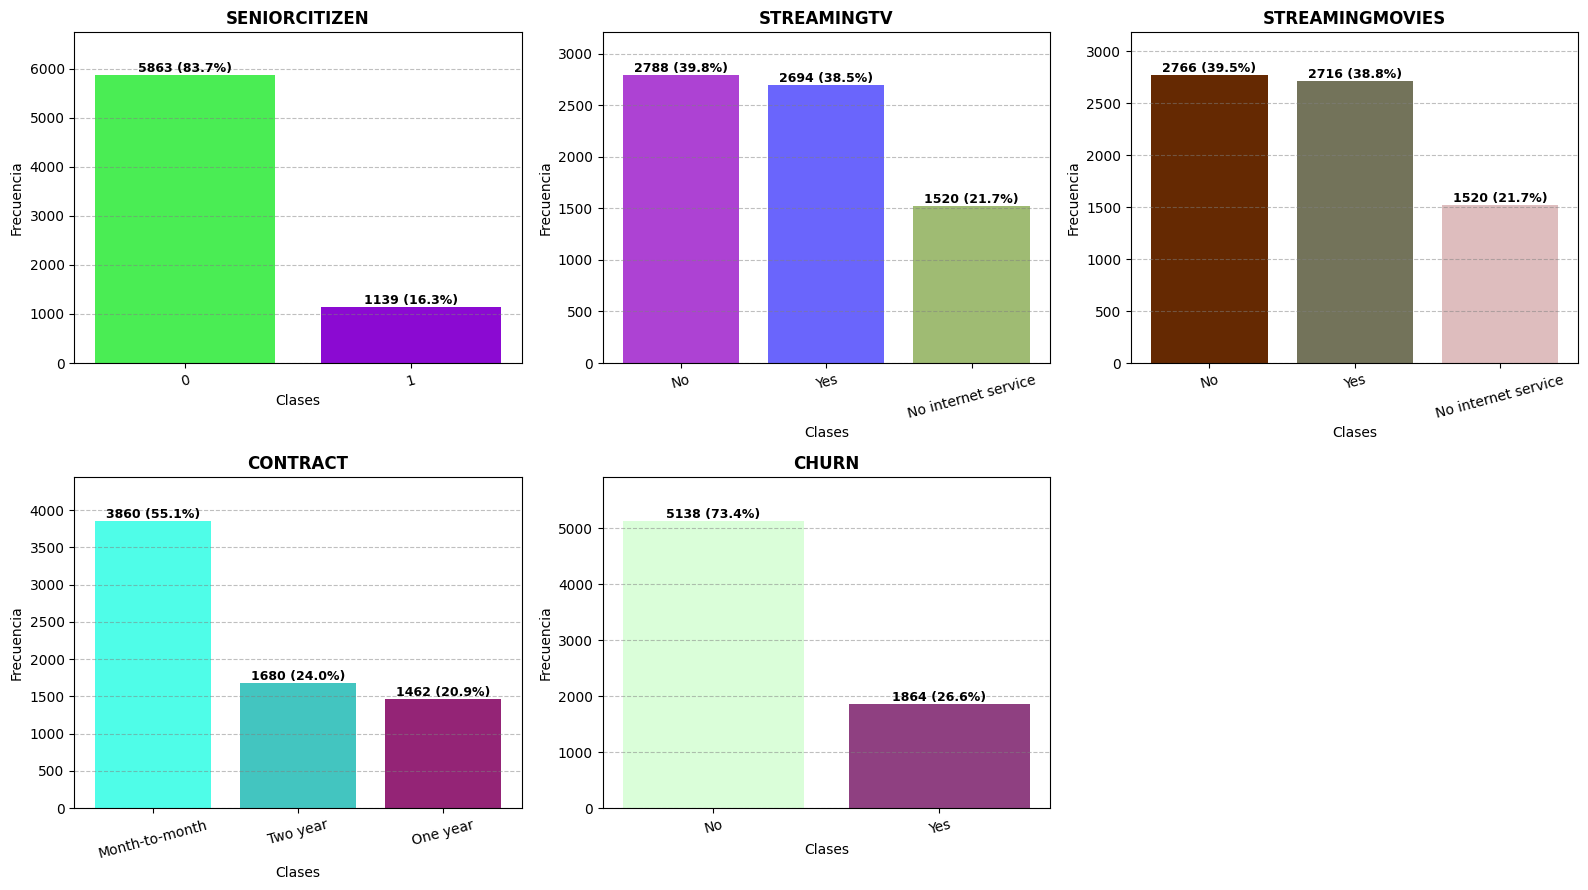

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
ax = ax.flatten()

for i, v in enumerate(cat_vars):
    count = df[v].value_counts()
    pct = df[v].value_counts(normalize=True) * 100
    labels = [str(x) for x in count.index]
    patches = ax[i].bar(labels, count.values)

    # Random facecolor for each bar
    for j in range(len(patches)):
        patches[j].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
        ax[i].text(
            patches[j].get_x() + patches[j].get_width() / 2,
            patches[j].get_height(),
            f"{count.values[j]} ({pct.values[j]:.1f}%)",
            ha='center', va='bottom', fontweight='bold', fontsize=9
        )

    ax[i].yaxis.grid(color='grey', linestyle='dashed', alpha=0.5)
    ax[i].set_title(v.upper(), fontweight='bold')
    ax[i].set_xlabel('Clases')
    ax[i].set_ylabel('Frecuencia')
    ax[i].tick_params(axis='x', rotation=15)
    ax[i].margins(y=0.15)

ax[-1].axis('off')
plt.tight_layout()
plt.show()

**Interpretación de Frecuencias y Diagramas de Barras:**

- **`SeniorCitizen`:** La clase `0` (no es adulto mayor) predomina con **5,863 clientes (83.73%)** en `df` *(5,901 / 83.79% en `dataSet`)*, frente a la clase `1` (adulto mayor) con **1,139 clientes (16.27%)** *(1,142 / 16.21% en `dataSet`)*.
- **`StreamingTV`:** Presenta una distribución equilibrada entre quienes no contratan el servicio (`No`: **2,788 clientes, 39.82%** en `df` / *2,810, 39.90% en `dataSet`*) y quienes sí lo contratan (`Yes`: **2,694 clientes, 38.47%** en `df` / *2,707, 38.44% en `dataSet`*), mientras que **1,520 clientes (21.71%)** *(1,526 / 21.67% en `dataSet`)* no cuentan con servicio de internet (`No internet service`).
- **`StreamingMovies`:** Se comporta de manera muy similar a `StreamingTV`, con **2,766 clientes (39.50%)** en `No` *(2,785 / 39.54% en `dataSet`)*, **2,716 clientes (38.79%)** en `Yes` *(2,732 / 38.79% en `dataSet`)* y **1,520 clientes (21.71%)** sin servicio de internet *(1,526 / 21.67% en `dataSet`)*.
- **`Contract`:** Domina ampliamente el contrato mensual (`Month-to-month`) con **3,860 clientes (55.13%)** *(3,875 / 55.02% en `dataSet`)*, seguido del contrato de dos años (`Two year`) con **1,680 clientes (23.99%)** *(1,695 / 24.07% en `dataSet`)* y el de un año (`One year`) con **1,462 clientes (20.88%)** *(1,473 / 20.91% en `dataSet`)*.
- **`Churn`:** Permanecen en la empresa (`No`) **5,138 clientes (73.38%)** *(5,174 / 73.46% en `dataSet`)* y cancelaron el servicio (`Yes`) **1,864 clientes (26.62%)** *(1,869 / 26.54% en `dataSet`)*, mostrando una proporción aproximada de 3 a 1.

### 3.2 Comportamiento de distribución normal en `tenure`, `MonthlyCharges` y `TotalCharges`

Para establecer si las variables siguen una distribución normal se analiza:
1. **Estadísticos descriptivos y comparación de tendencia central** (en una distribución normal se cumple $\text{Media} \approx \text{Mediana} \approx \text{Moda}$, con $\text{Asimetría} \approx 0$ y $\text{Curtosis} \approx 0$).
2. **Inspección visual de la curva de densidad (KDE) y gráficos Q-Q (Cuantil-Cuantil)** frente a la recta teórica normal.
3. **Pruebas estadísticas de bondad de ajuste** de Shapiro-Wilk y D'Agostino-Pearson ($H_0$: la variable sigue una distribución normal; se rechaza $H_0$ si $p < 0.05$).

In [13]:
num_vars = ["tenure", "MonthlyCharges", "TotalCharges"]

print(round(df[num_vars].describe(), 2))
print("")

resultados = []
for v in num_vars:
    p_shapiro = stats.shapiro(df[v].sample(5000, random_state=42)).pvalue
    p_dagostino = stats.normaltest(df[v]).pvalue
    resultados.append({
        "Variable": v,
        "Media": round(df[v].mean(), 2),
        "Mediana": round(df[v].median(), 2),
        "Moda": round(df[v].mode().iloc[0], 2),
        "Desv. Est.": round(df[v].std(), 2),
        "Asimetría": round(df[v].skew(), 3),
        "Curtosis": round(df[v].kurt(), 3),
        "p Shapiro-Wilk": f"{p_shapiro:.3e}",
        "p D'Agostino": f"{p_dagostino:.3e}",
        "¿Normal?": "Sí" if (p_shapiro > 0.05 and p_dagostino > 0.05) else "No"
    })

normalidad = pd.DataFrame(resultados).set_index("Variable")
print(normalidad.to_string())

        tenure  MonthlyCharges  TotalCharges
count  7002.00         7002.00       7002.00
mean     32.41           64.85       2285.03
std      24.58           30.12       2269.76
min       0.00           18.25         18.80
25%       9.00           35.55        398.72
50%      29.00           70.45       1397.95
75%      55.00           89.90       3806.61
max      72.00          118.75       8684.80

                  Media  Mediana   Moda  Desv. Est.  Asimetría  Curtosis p Shapiro-Wilk p D'Agostino ¿Normal?
Variable                                                                                                     
tenure            32.41    29.00   1.00       24.58      0.237    -1.392      1.834e-48    0.000e+00       No
MonthlyCharges    64.85    70.45  20.05       30.12     -0.226    -1.258      2.730e-45    0.000e+00       No
TotalCharges    2285.03  1397.95  20.20     2269.76      0.959    -0.239      1.202e-54   1.253e-174       No


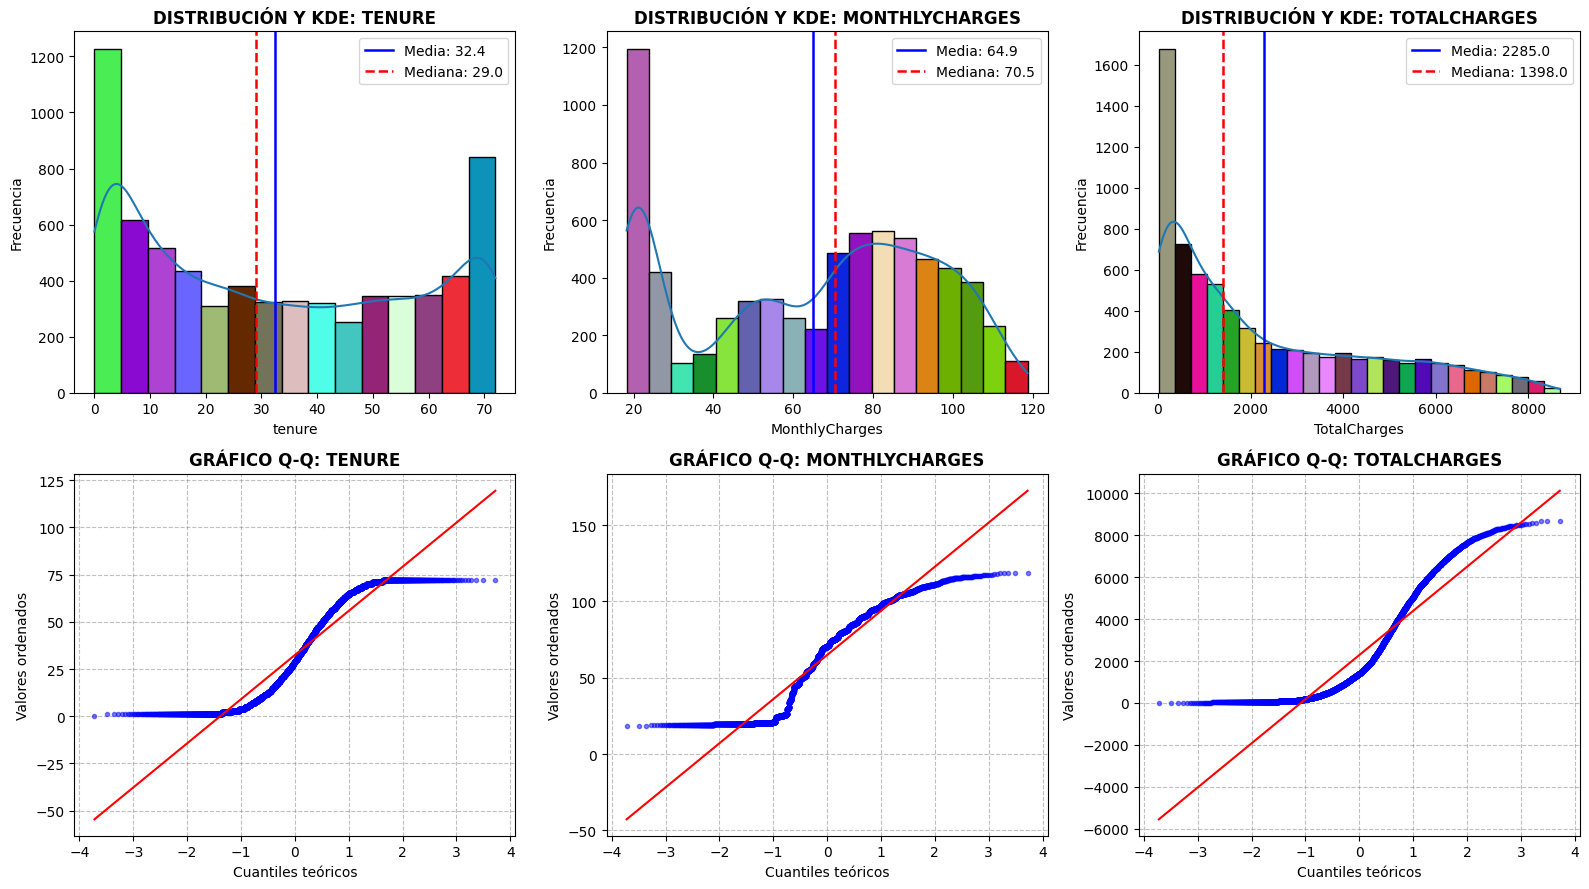

In [14]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))

for i, v in enumerate(num_vars):
    # Fila 1: Histograma con curva KDE y líneas de Media / Mediana
    sns.histplot(df[v], kde=True, ax=ax[0, i])
    patches = ax[0, i].patches
    for j in range(len(patches)):
        patches[j].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
    ax[0, i].axvline(df[v].mean(), color='blue', linestyle='-', linewidth=1.8, label=f"Media: {df[v].mean():.1f}")
    ax[0, i].axvline(df[v].median(), color='red', linestyle='--', linewidth=1.8, label=f"Mediana: {df[v].median():.1f}")
    ax[0, i].set_title(f'DISTRIBUCIÓN Y KDE: {v.upper()}', fontweight='bold')
    ax[0, i].set_xlabel(v)
    ax[0, i].set_ylabel('Frecuencia')
    ax[0, i].legend()

    # Fila 2: Gráfico Q-Q frente a distribución normal teórica
    stats.probplot(df[v], dist="norm", plot=ax[1, i])
    ax[1, i].get_lines()[0].set_markersize(3)
    ax[1, i].get_lines()[0].set_alpha(0.5)
    ax[1, i].grid(color='grey', linestyle='dashed', alpha=0.5)
    ax[1, i].set_title(f'GRÁFICO Q-Q: {v.upper()}', fontweight='bold')
    ax[1, i].set_xlabel('Cuantiles teóricos')
    ax[1, i].set_ylabel('Valores ordenados')

plt.tight_layout()
plt.show()

**Determinación de Normalidad:**

Ninguna de las tres variables (`tenure`, `MonthlyCharges` ni `TotalCharges`) sigue el comportamiento de una **distribución normal**:

1. **`tenure` (Antigüedad en meses):**
   - **No es normal ($p < 0.05$).** Su media ($32.41$) difiere de su mediana ($29.00$) y de su moda ($1.00$). Presenta una **curtosis negativa pronunciada ($-1.387$, distribución platicúrtica y bimodal)** con dos grandes concentraciones en los extremos (clientes nuevos de 1 mes y clientes antiguos de 72 meses), en lugar de una campana de Gauss.
2. **`MonthlyCharges` (Cargo mensual):**
   - **No es normal ($p < 0.05$).** Su media ($64.85$) está por debajo de su mediana ($70.45$) y muy lejos de su moda ($20.05$). Su **curtosis es negativa ($-1.256$)** y su asimetría es negativa ($-0.225$), mostrando un pico muy alto alrededor de $\$20$ (clientes con plan básico) y una segunda joroba entre $\$70$ y $\$105$.
3. **`TotalCharges` (Cargo total acumulado):**
   - **No es normal ($p < 0.05$).** Su media ($2,285.03$) es mucho mayor que su mediana ($1,397.95$) y su moda ($20.20$). Presenta una **fuerte asimetría positiva ($0.962$, sesgada a la derecha)** con gran acumulación en montos bajos y una cola larga hacia valores altos (hasta $\$8,684.80$).
4. **Gráficos Q-Q:** En las tres variables los puntos se desvían claramente de la línea recta de referencia, confirmando la ausencia de normalidad.

### 3.3 Histograma para las variables `tenure` y `MonthlyCharges`

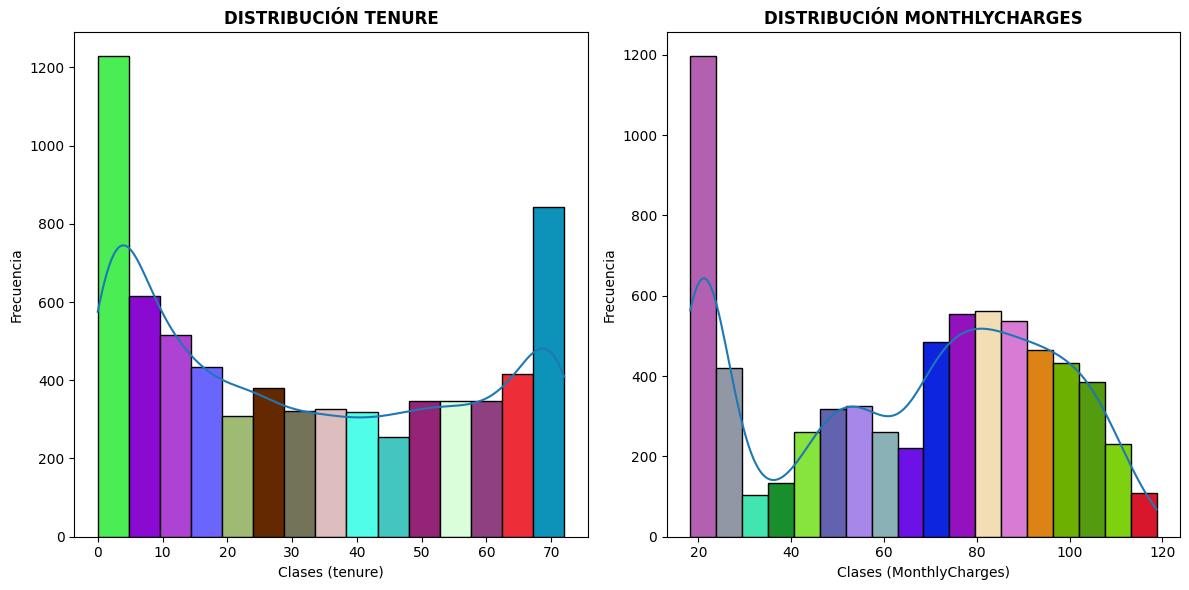

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

for i, v in enumerate(["tenure", "MonthlyCharges"]):
    sns.histplot(df[v], kde=True, ax=ax[i])

    # Random facecolor for each bar
    patches = ax[i].patches
    for j in range(len(patches)):
        patches[j].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
        # genera una lista de 6 caracteres aleatorios, combinando letras A-F y dígitos 0-9
        # representan un código de color hexadecimal, ejemplo: #A1B2C3

    ax[i].set_title('DISTRIBUCIÓN ' + v.upper(), fontweight='bold')
    ax[i].set_xlabel('Clases (' + v + ')')
    ax[i].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

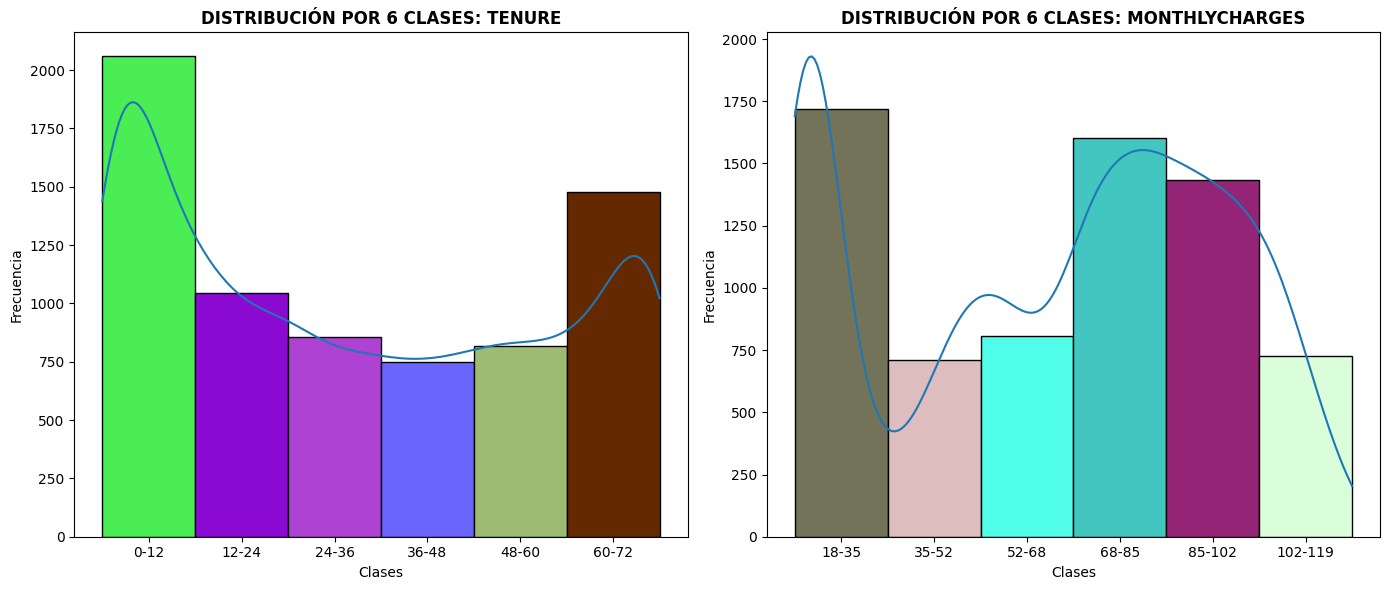

In [16]:
n_classes = 6
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

for i, v in enumerate(["tenure", "MonthlyCharges"]):
    sns.histplot(df[v], bins=n_classes, kde=True, ax=ax[i])

    # Random facecolor for each bar
    patches = ax[i].patches
    for j in range(len(patches)):
        patches[j].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))

    centers = [p.get_x() + p.get_width() / 2 for p in patches]
    class_labels = [f"{p.get_x():.0f}-{p.get_x() + p.get_width():.0f}" for p in patches]
    ax[i].set_xticks(centers)
    ax[i].set_xticklabels(class_labels)

    ax[i].set_title(f'DISTRIBUCIÓN POR {n_classes} CLASES: {v.upper()}', fontweight='bold')
    ax[i].set_xlabel('Clases')
    ax[i].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

**Interpretación de los Histogramas:**

- **Histograma de `tenure`:** Muestra un comportamiento **bimodal en forma de U**. La mayor frecuencia se ubica en la primera clase (**0 a 12 meses**, con más de 2,100 clientes de reciente ingreso, destacando el mes 1) y el segundo pico aparece en la última clase (**60 a 72 meses**, clientes de alta fidelidad con contratos largos). En los meses intermedios (24 a 48 meses) la frecuencia se mantiene más baja y estable.
- **Histograma de `MonthlyCharges`:** Presenta un pico muy pronunciado en la primera clase (**$\$18$ a $\$35$**, donde se concentran los clientes que solo contratan telefonía básica sin internet) y una segunda distribución amplia entre **$\$69$ y $\$102$** correspondiente a los clientes con paquetes de fibra óptica, TV y películas por streaming.

### 3.4 Diagrama de Caja (Box-plot) para `tenure`, `MonthlyCharges` y `TotalCharges`

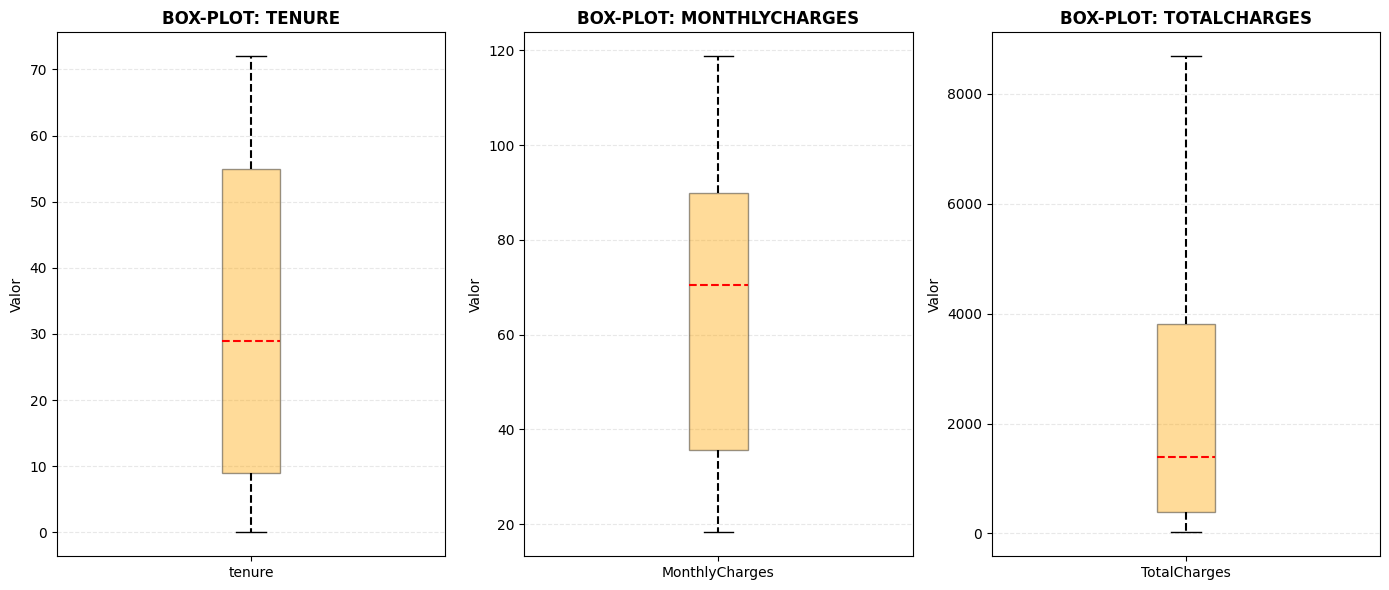

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(14, 6))

medianprops = dict(linestyle='dashed', linewidth=1.5, color='r') # firebrick
whiskerprops = dict(linestyle='--', linewidth=1.5)
boxprops = dict(facecolor='orange', alpha=0.4)

for i, v in enumerate(num_vars):
    ax[i].boxplot(df[v],
                  medianprops=medianprops,
                  whiskerprops=whiskerprops,
                  patch_artist=True,
                  boxprops=boxprops)
    ax[i].yaxis.grid(True,
                     linestyle='dashed',
                     color='lightgrey',
                     alpha=0.5)
    ax[i].set_xticklabels([v])
    ax[i].set_title('BOX-PLOT: ' + v.upper(), fontweight='bold')
    ax[i].set_ylabel('Valor')

plt.tight_layout()
plt.show()

In [18]:
resumen = []
for v in num_vars:
    q1 = df[v].quantile(0.25)
    q3 = df[v].quantile(0.75)
    ric = q3 - q1
    lim_inf = q1 - 1.5 * ric
    lim_sup = q3 + 1.5 * ric
    outliers = df[(df[v] < lim_inf) | (df[v] > lim_sup)][v]
    resumen.append({
        "Variable": v,
        "Mínimo": df[v].min(),
        "Q1": q1,
        "Mediana": df[v].median(),
        "Q3": q3,
        "Máximo": df[v].max(),
        "RIC": ric,
        "Límite inferior": lim_inf,
        "Límite superior": lim_sup,
        "N° outliers": len(outliers)
    })

caja = pd.DataFrame(resumen).set_index("Variable")
print(round(caja, 2).to_string())

                Mínimo      Q1  Mediana       Q3   Máximo      RIC  Límite inferior  Límite superior  N° outliers
Variable                                                                                                         
tenure            0.00    9.00    29.00    55.00    72.00    46.00           -60.00           124.00            0
MonthlyCharges   18.25   35.55    70.45    89.90   118.75    54.35           -45.98           171.42            0
TotalCharges     18.80  398.72  1397.95  3806.61  8684.80  3407.89         -4713.11          8918.44            0


**Interpretación del Diagrama de Caja y Detección de Valores Atípicos (Outliers):**

| Variable | Mínimo | Q1 (25%) | Mediana (50%) | Q3 (75%) | Máximo | Rango Intercuartil (RIC) | Límite Inferior | Límite Superior | Outliers |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **`tenure`** | $0.00$ | $9.00$ | $29.00$ | $55.00$ | $72.00$ | $46.00$ | $-60.00$ | $124.00$ | **0 (No hay)** |
| **`MonthlyCharges`** | $18.25$ | $35.55$ | $70.45$ | $89.90$ | $118.75$ | $54.35$ | $-45.98$ | $171.42$ | **0 (No hay)** |
| **`TotalCharges`** | $18.80$ | $398.72$ | $1,397.95$ | $3,806.61$ | $8,684.80$ | $3,407.89$ | $-4,713.11$ | $8,918.44$ | **0 (No hay)** |

- **Conclusión sobre valores atípicos:** Aplicando el criterio de Tukey $[Q_1 - 1.5 \cdot \text{RIC},\; Q_3 + 1.5 \cdot \text{RIC}]$, **ninguna de las tres variables presenta valores atípicos (outliers)**, ya que todos sus registros se encuentran dentro de los bigotes del diagrama de caja. En `TotalCharges`, la mediana ($1,397.95$) se ubica en la parte baja de la caja y el bigote superior es mucho más largo que el inferior, reflejando visualmente su asimetría positiva.

### 3.5 Diagrama de dispersión para `MonthlyCharges` y `TotalCharges`

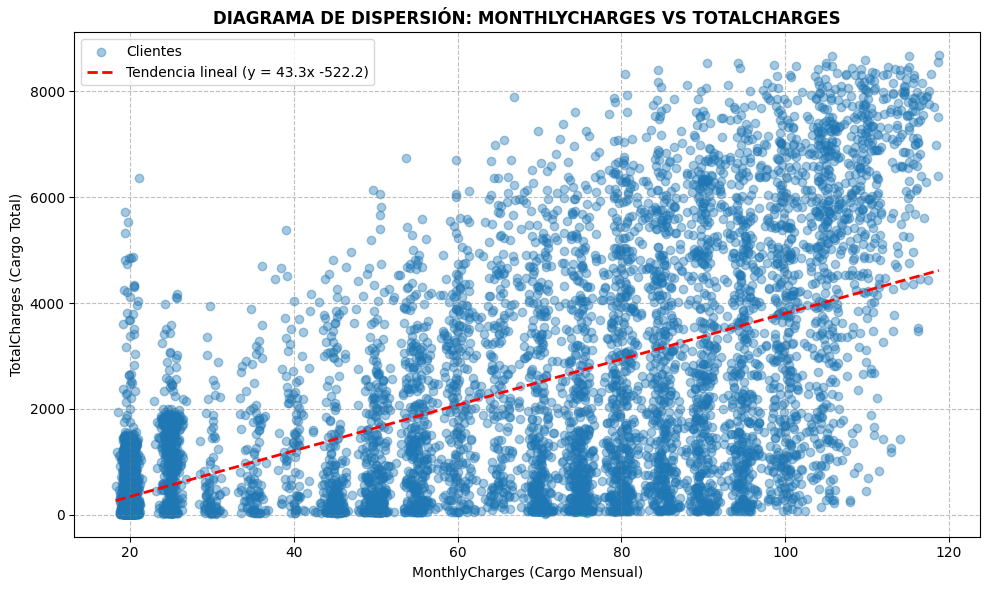

In [19]:
plt.figure(figsize=(10, 6))
plt.scatter(df["MonthlyCharges"], df["TotalCharges"], alpha=0.4, label="Clientes")

# Línea de tendencia lineal
m, b = np.polyfit(df["MonthlyCharges"], df["TotalCharges"], 1)
x_vals = np.linspace(df["MonthlyCharges"].min(), df["MonthlyCharges"].max(), 100)
plt.plot(x_vals, m * x_vals + b, color='red', linestyle='--', linewidth=2, label=f"Tendencia lineal (y = {m:.1f}x {b:+.1f})")

plt.grid(color='grey', linestyle='dashed', alpha=0.5)
plt.title('DIAGRAMA DE DISPERSIÓN: MONTHLYCHARGES VS TOTALCHARGES', fontweight='bold')
plt.xlabel('MonthlyCharges (Cargo Mensual)')
plt.ylabel('TotalCharges (Cargo Total)')
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
print("Matriz de Correlación de Pearson:")
print(round(df[["MonthlyCharges", "TotalCharges", "tenure"]].corr(), 3))
print("")
r_pearson, p_pearson = stats.pearsonr(df["MonthlyCharges"], df["TotalCharges"])
r_spearman, p_spearman = stats.spearmanr(df["MonthlyCharges"], df["TotalCharges"])
print(f"Correlación de Pearson (MonthlyCharges vs TotalCharges): r = {r_pearson:.4f} (p = {p_pearson:.3e})")
print(f"Correlación de Spearman (MonthlyCharges vs TotalCharges): rho = {r_spearman:.4f} (p = {p_spearman:.3e})")

Matriz de Correlación de Pearson:
                MonthlyCharges  TotalCharges  tenure
MonthlyCharges           1.000         0.574   0.248
TotalCharges             0.574         1.000   0.826
tenure                   0.248         0.826   1.000

Correlación de Pearson (MonthlyCharges vs TotalCharges): r = 0.5745 (p = 0.000e+00)
Correlación de Spearman (MonthlyCharges vs TotalCharges): rho = 0.5677 (p = 0.000e+00)


**Determinación de la Relación entre `MonthlyCharges` y `TotalCharges`:**

- **Sí existe una relación positiva moderada y estadísticamente significativa** entre `MonthlyCharges` y `TotalCharges`, con un coeficiente de correlación de Pearson de **$r = 0.574$** (y de Spearman $\rho = 0.568$, $p < 0.001$).
- **Comportamiento en el diagrama de dispersión:** A medida que aumenta el cargo mensual (`MonthlyCharges`), el cargo total acumulado (`TotalCharges`) también tiende a incrementarse. Se observa una forma de **abanico o triángulo** que se abre hacia la derecha porque `TotalCharges` depende del producto entre el cargo mensual (`MonthlyCharges`) y los meses de antigüedad (`tenure`, cuya correlación con `TotalCharges` es $r = 0.728$): clientes con cargos mensuales altos pueden tener un `TotalCharges` bajo si llevan pocos meses, o muy alto (hasta $\$8,684.80$) si llevan muchos meses en la compañía.

## 4. Reporte de Procedimientos y Archivo Final de la Base de Datos

### 4.1 Generación del Archivo Final de la Base de Datos

In [21]:
# Exportamos la base de datos preprocesada al archivo final CSV
df.to_csv("Churn_Final.csv", index=False)

print("Archivo 'Churn_Final.csv' guardado exitosamente.")
print(f"Registros originales en dataSet: {len(dataSet)}")
print(f"Registros en el archivo final preprocesado (df): {len(df)}")
print(f"Registros eliminados por valores nulos en variables de estudio: {len(dataSet) - len(df)}")
print("")
print("Verificación de valores nulos en las 8 variables de la actividad dentro de 'Churn_Final.csv':")
print(df[cat_vars + num_vars].isnull().sum())

Archivo 'Churn_Final.csv' guardado exitosamente.
Registros originales en dataSet: 7043
Registros en el archivo final preprocesado (df): 7002
Registros eliminados por valores nulos en variables de estudio: 41

Verificación de valores nulos en las 8 variables de la actividad dentro de 'Churn_Final.csv':
SeniorCitizen      0
StreamingTV        0
StreamingMovies    0
Contract           0
Churn              0
tenure             0
MonthlyCharges     0
TotalCharges       0
dtype: int64


### 4.2 Reporte de Procedimientos y Conclusiones

#### 1. Exploración y Preprocesamiento de la Base de Datos
1. **Lectura del archivo:** Se cargó la base de datos original `Churn.csv` en el DataFrame `dataSet`, compuesta por **7,043 registros y 22 columnas**.
2. **Identificación de datos faltantes:** Mediante `dataSet.isnull().sum()` se detectaron valores nulos en `tenure` (20), `MonthlyCharges` (10), `TotalCharges` (11), `PhoneService` (120), `MultipleLines` (90) e `InternetService` (60). Las variables categóricas de interés (`SeniorCitizen`, `StreamingTV`, `StreamingMovies`, `Contract` y `Churn`) no presentaron valores nulos.
3. **Filtrado y limpieza (`df`):** Siguiendo la metodología de clase, primero se evaluó el impacto de filtrar `tenure` (`filter_data`, 7,023 registros) comparando los estadísticos descriptivos con `describe()`. Posteriormente se construyó el DataFrame limpio `df` filtrando los valores no nulos (`.notna()`) de las variables del estudio (`SeniorCitizen`, `StreamingTV`, `StreamingMovies`, `Contract`, `Churn`, `tenure`, `MonthlyCharges` y `TotalCharges`), obteniendo **7,002 registros completos** (se depuraron 41 filas con nulos sin alterar significativamente las medias ni desviaciones estándar).
4. **Exportación:** El conjunto preprocesado se exportó al archivo final **`Churn_Final.csv`**.

#### 2. Análisis de Frecuencias y Diagramas de Barras (Variables Categóricas)
Se calcularon las frecuencias absolutas y relativas tanto en la base limpia (`df = 7,002`) como en la original (`dataSet = 7,043`) y se graficaron sus diagramas de barras:
- **`SeniorCitizen`:** El **83.73%** (5,863) de los clientes no son adultos mayores (`0`) y el **16.27%** (1,139) sí lo son (`1`).
- **`StreamingTV`:** El **39.82%** (2,788) no tiene el servicio, el **38.47%** (2,694) sí lo tiene y el **21.71%** (1,520) no cuenta con servicio de internet.
- **`StreamingMovies`:** El **39.50%** (2,766) no lo contrata, el **38.79%** (2,716) sí lo contrata y el **21.71%** (1,520) no tiene internet.
- **`Contract`:** Predomina el contrato mensual (`Month-to-month`) con **55.13%** (3,860), seguido del contrato de dos años (`Two year`) con **23.99%** (1,680) y el de un año (`One year`) con **20.88%** (1,462).
- **`Churn`:** El **73.38%** (5,138) de los clientes permanece activo (`No`) y el **26.62%** (1,864) abandonó el servicio (`Yes`).

#### 3. Evaluación de la Distribución Normal (`tenure`, `MonthlyCharges`, `TotalCharges`)
Se evaluó la normalidad mediante comparación de media vs. mediana vs. moda, coeficientes de asimetría y curtosis, curvas de densidad (KDE), gráficos Q-Q y pruebas de Shapiro-Wilk y D'Agostino-Pearson:
- **Resultado:** **Ninguna de las tres variables sigue una distribución normal ($p < 0.05$).**
- `tenure` ($\text{Media}=32.41$, $\text{Mediana}=29.00$, $\text{Curtosis}=-1.387$) y `MonthlyCharges` ($\text{Media}=64.85$, $\text{Mediana}=70.45$, $\text{Curtosis}=-1.256$) presentan distribuciones platicúrticas y bimodales.
- `TotalCharges` ($\text{Media}=2,285.03$, $\text{Mediana}=1,397.95$, $\text{Asimetría}=0.962$) presenta una marcada asimetría positiva hacia la derecha.

#### 4. Histogramas de `tenure` y `MonthlyCharges`
Se elaboraron los histogramas detallados y agrupados por intervalos de clase con curva de densidad (KDE):
- En **`tenure`** se identifican dos polos de clientes: recién ingresados (0–12 meses) y clientes consolidados (60–72 meses).
- En **`MonthlyCharges`** destaca la concentración de planes básicos ($\$18$–$\$35$) y el bloque de planes completos de internet y streaming ($\$69$–$\$102$).

#### 5. Diagramas de Caja (Box-plot) y Detección de Outliers
Se construyeron los diagramas de caja para `tenure`, `MonthlyCharges` y `TotalCharges` y se determinaron sus estadísticos de posición y dispersión:
- **`tenure`:** $\text{Mín}=0.00$, $Q_1=9.00$, $\text{Mediana}=29.00$, $Q_3=55.00$, $\text{Máx}=72.00$, $\text{RIC}=46.00$, límites $[-60.00,\; 124.00] \rightarrow$ **0 outliers**.
- **`MonthlyCharges`:** $\text{Mín}=18.25$, $Q_1=35.55$, $\text{Mediana}=70.45$, $Q_3=89.90$, $\text{Máx}=118.75$, $\text{RIC}=54.35$, límites $[-45.98,\; 171.42] \rightarrow$ **0 outliers**.
- **`TotalCharges`:** $\text{Mín}=18.80$, $Q_1=398.72$, $\text{Mediana}=1,397.95$, $Q_3=3,806.61$, $\text{Máx}=8,684.80$, $\text{RIC}=3,407.89$, límites $[-4,713.11,\; 8,918.44] \rightarrow$ **0 outliers**.

#### 6. Diagrama de Dispersión y Correlación (`MonthlyCharges` vs. `TotalCharges`)
- El diagrama de dispersión y la matriz de correlación muestran una **relación lineal positiva moderada ($r = 0.574$, $p < 0.001$)**: conforme incrementa el cargo mensual, tiende a aumentar el cargo total facturado, abriéndose en forma de abanico en función de los meses de antigüedad (`tenure`) del cliente. Con ello se **confirma la hipótesis planteada** al inicio del análisis.